# Language modeling is one of the fundamental concepts behind AI systems such as ChatGPT, Gemini, and Claude. Since you are working with Harry Potter text and want to build your own language model in Python, let's understand it from that perspective.
1. What is language modeling?
Language modeling is the process of learning patterns in language so that a model can estimate the probability of a sequence of words or predict what token is likely to come next.

Imagine your training data contains this sentence:
Harry Potter lived with his aunt and uncle.

During training, a simple language model learns patterns such as:
- After Harry, the next word might be Potter.
- After Harry Potter, the next word might be lived.
- After Harry Potter lived with his, the next word might be aunt.
The model learns these patterns from its training data instead of needing you to manually program every sentence.

In [1]:
from collections import Counter
import nltk
import numpy as np
import torch
from nltk.tokenize import word_tokenize
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
from torch.optim import Adam
from torchinfo import summary
from torchmetrics.classification import MulticlassAccuracy

nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to /home/mmhe/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/mmhe/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/mmhe/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [2]:
torch.set_num_threads(10)
torch.manual_seed(67)

In [3]:
with open("harry_potter_series_pure_story_split_lines.txt", "r", encoding="utf-8") as f:
    hPRaw = f.read()
    hPLines = hPRaw.splitlines()

tokens = word_tokenize(hPRaw.lower())
len(tokens)

1422108

In [4]:
vocab = {"<UNK>": 0}

for token in Counter(tokens).keys():  # noqa: SIM118
    if token not in vocab:
        vocab[token] = len(vocab)

len(vocab)

22717

In [5]:
def textToIdx(sentence, vocab):
    index = []

    for token in word_tokenize(sentence.lower()):
        if token in vocab:
            index.append(vocab[token])
        else:
            index.append(vocab["<UNK>"])
    return index

In [6]:
textToIdx("Harry is a good boy!", vocab= vocab)

[403, 889, 47, 146, 97, 295]

In [7]:
sentenceInNumForm = []

for line in hPLines:
    sentenceInNumForm.append(textToIdx(sentence = line, vocab = vocab))
len(sentenceInNumForm), len(hPLines)

(89406, 89406)

In [8]:
trainingSequence = []

for sentence in sentenceInNumForm:
    for seq in range(1, len(sentence)):
        trainingSequence.append(sentence[:seq + 1])

len(trainingSequence)

1332771

In [9]:
maxLength = 0
for seq in trainingSequence:
    l = len(seq)
    if maxLength < l:
        maxLength = l
    
maxLength

69

In [10]:
paddedTrainingSequence = []

for seq in trainingSequence:
    paddedTrainingSequence.append(([0] * (maxLength - len(seq))) + seq)
len(paddedTrainingSequence)

1332771

In [11]:
paddedTrainingSequence = torch.tensor(paddedTrainingSequence, dtype= torch.long)

X = paddedTrainingSequence[:, :-1]
y = paddedTrainingSequence[:, -1]
len(X), len(y)

(1332771, 1332771)

In [12]:
X, y

(tensor([[  0,   0,   0,  ...,   0,   0,   1],
         [  0,   0,   0,  ...,   0,   1,   2],
         [  0,   0,   0,  ...,   1,   2,   3],
         ...,
         [  0,   0,   0,  ...,   0,   0, 171],
         [  0,   0,   0,  ...,   0, 171,  45],
         [  0,   0,   0,  ..., 171,  45, 579]]),
 tensor([  2,   3,   4,  ...,  45, 579,  23]))

In [13]:
class CusDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [14]:
trainDataset = CusDataset(X, y)
len(trainDataset)

1332771

In [15]:
trainLoader = DataLoader(trainDataset, batch_size= 128, shuffle= True)
len(trainLoader)

10413

In [16]:
class LstmModel(nn.Module):
    def __init__(self, vocabSize):
        super().__init__()
        self.embed = nn.Embedding(num_embeddings=vocabSize, embedding_dim=64)
        self.lstm = nn.LSTM(input_size= 64, hidden_size= 128, dropout= 0.25, batch_first= True, num_layers= 2)
        self.neuralNet = nn.Sequential(
            nn.Linear(in_features=128, out_features=128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(in_features=128, out_features=128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(in_features= 128, out_features= vocabSize)
        )

    def forward(self, X):
        _, (X, __) = self.lstm(self.embed(X))
        return self.neuralNet(X[-1])
model = LstmModel(vocabSize= len(vocab))

In [17]:
summary(model= model)

Layer (type:depth-idx)                   Param #
LstmModel                                --
├─Embedding: 1-1                         1,453,888
├─LSTM: 1-2                              231,424
├─Sequential: 1-3                        --
│    └─Linear: 2-1                       16,512
│    └─BatchNorm1d: 2-2                  256
│    └─ReLU: 2-3                         --
│    └─Dropout: 2-4                      --
│    └─Linear: 2-5                       16,512
│    └─BatchNorm1d: 2-6                  256
│    └─ReLU: 2-7                         --
│    └─Dropout: 2-8                      --
│    └─Linear: 2-9                       2,930,493
Total params: 4,649,341
Trainable params: 4,649,341
Non-trainable params: 0

In [18]:
alpha = 0.0001
accFunc = MulticlassAccuracy(num_classes= len(vocab))
lossHist = []
accHist = []

In [19]:
optim = Adam(model.parameters(), lr= alpha)
lossFunc = nn.CrossEntropyLoss()

In [59]:
for param_group in optim.param_groups:
    param_group['lr'] = 0.0008

In [60]:
epochs = 1

for epoch in range(epochs):
    model.train()
    lossAvg = 0
    

    for X, y in trainLoader:
        yHat = model(X)
        loss = lossFunc(yHat, y)
        optim.zero_grad()
        loss.backward()
        optim.step()

        #accAvg += accFunc(yHat, y).item()
        lossAvg += loss.item()
        #print("forward done")
    #accAvg /= len(trainLoader)
    lossAvg /= len(trainLoader)
    lossHist.append(lossAvg)
    #accHist.append(accAvg)
    print(f"Epoch {epoch + 1} | Training loss= {lossAvg}\n============================================================================================")


Epoch 1 | Training loss= 4.686962461741733


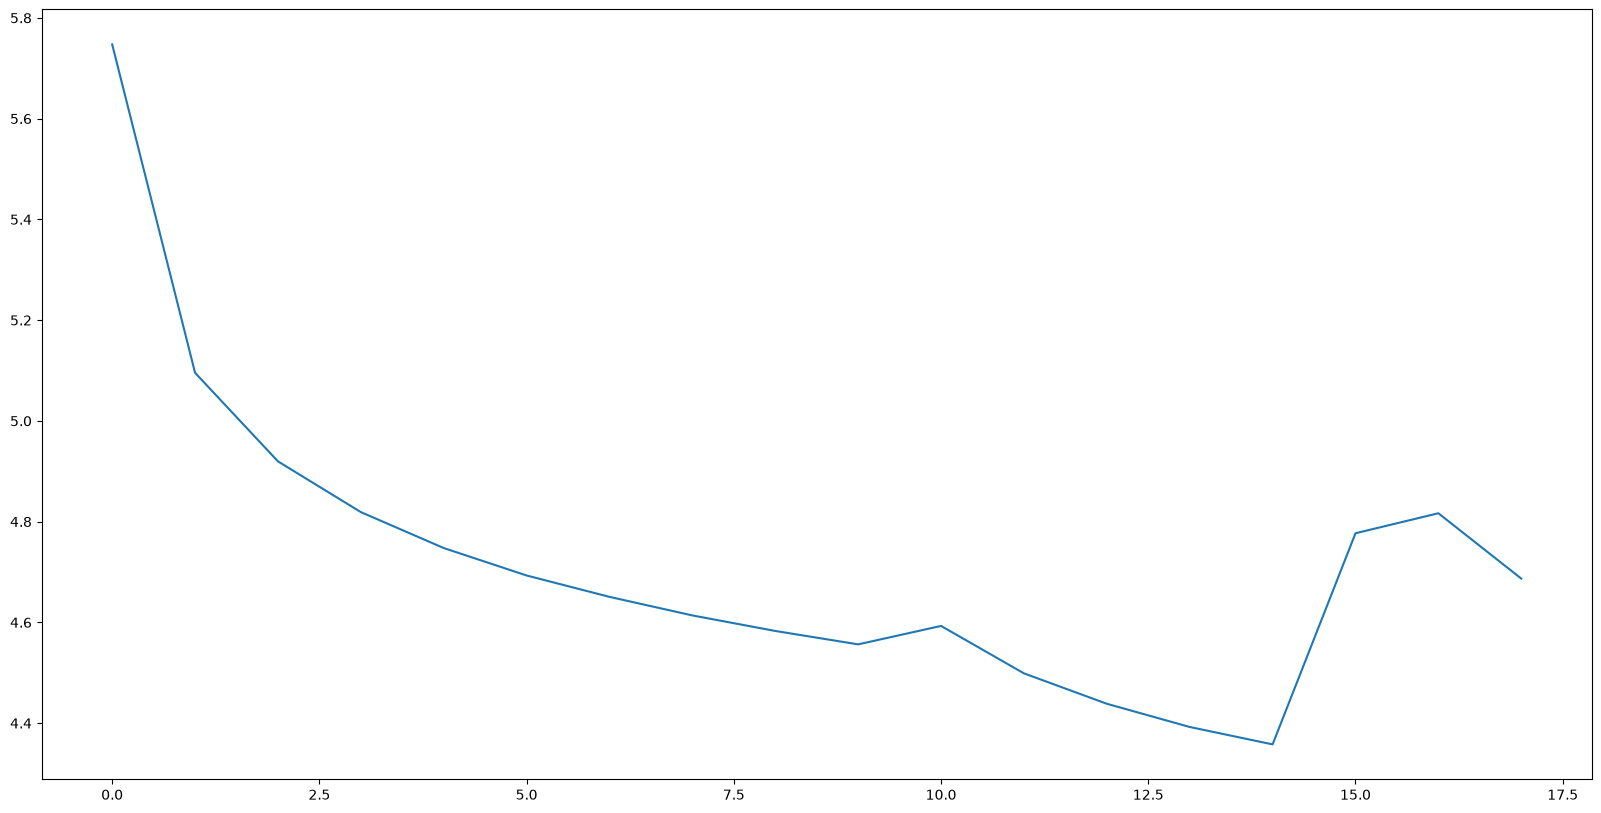

In [61]:
import matplotlib.pyplot as plt 

plt.figure(figsize=(20, 10))
plt.plot(lossHist)
plt.show()

In [62]:
def pred(model, vocab, userText):

    textNumForm = textToIdx(sentence= userText, vocab= vocab)

    paddedNumForm = [(([0] * (maxLength - len(textNumForm))) + textNumForm)]

    #paddedNumForm = torch.tensor(paddedNumForm, dtype= torch.long)

    paddedNumForm = torch.tensor([textNumForm], dtype= torch.long)

    with torch.no_grad():

        yHat = list(vocab.keys())[torch.argmax((model(paddedNumForm)), dim= 1).item()]

        punctuation = [
        ".", ",", "!", "?", ";", ":",
        "...", "…",
        ")", "]", "}",
        "%", 
        "”", "’", "»"]

        if yHat in punctuation:
            return userText + yHat
        else:
            return userText + " " + yHat


In [63]:
model.eval()

totalTokenToGen = 30

userText = "The white queen smashed"

for i in range(totalTokenToGen):
    userText = pred(model= model, vocab= vocab, userText= userText)

print(userText)

The white queen smashed.. the, the door, and the, the door, and the, the door, and the, the door, and the, the door


In [64]:
accAvg = 0
model.eval()
with torch.no_grad():
    for X, y in trainLoader:
        yHat = model(X)
        acc = accFunc(yHat, y).item()
        accAvg += acc
        print(acc * 100)
    print(f"Model Accuracy: {(accAvg / len(trainLoader)) * 100:.2f}%")

13.475322723388672
12.193877249956131
12.29608729481697
13.371610641479492
5.4962407797575
17.189839482307434
12.520481646060944
10.11551097035408
7.93650820851326
12.710870802402496
12.89965957403183
12.318839877843857
13.707482814788818
12.149439007043839
8.810701966285706
11.971946805715561
9.756728261709213


KeyboardInterrupt: 

In [65]:
model.eval()
torch.save(model.state_dict(), "LangModel.pth")

import json

with open("vocabulary.json", "w", encoding="utf-8") as f:
    json.dump(vocab, f, ensure_ascii=False)
